# WP12 — Gemma3 1B model değişimi ve koşullu smoke hazırlığı
Kullanıcı yeni modeli seçti. Bu notebook gerçek cache/ölçüm/QA okur; Ollama API, model indirme veya inference içermez. Eski Qwen kayıtları ve19 senaryo korunur.

In [1]:
from pathlib import Path
import json,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd();Q=ROOT/'reports/qa/WP12/gemma1b_candidate_v1'
i=json.loads((Q/'model_identity.json').read_text(encoding='utf-8'));h=json.loads((Q/'hardware_snapshot.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'Aday':i['candidate_id'],'Yerel manifest':i['local_manifest_digest'],'Üst kaynak manifest':i['source_manifest_digest'],'Bütün hashler':i['all_content_hashes_valid'],'API digest':i['API_reported_digest']}]).T)
display(pd.DataFrame(i['config_and_layers'])[['mediaType','size','digest','valid']])

,0
Aday,WP12-gemma3-1b-it-q4_K_M-candidate-v1
Yerel manifest,sha256:313f48e331f7326ce703657512ab64022d8813b...
Üst kaynak manifest,sha256:97558784bdc9175075a72655bf360b15da17df6...
Bütün hashler,True
API digest,None


,mediaType,size,digest,valid
0,application/vnd.docker.container.image.v1+json,140,sha256:76a6b777faea7a8fda1d339bfc81ea919ed429c...,True
1,application/vnd.ollama.image.model,806058400,sha256:2f8c3d137f2496dcb4019e17a50f2974b89c1be...,True
2,application/vnd.ollama.image.template,358,sha256:e0a42594d802e5d31cdc786deb4823edb8adff6...,True
3,application/vnd.ollama.image.license,8432,sha256:dd084c7d92a3c1c14cc09ae77153b903fd2024b...,True
4,application/vnd.ollama.image.params,77,sha256:3116c52250752e00dd06b16382e952bd33c34fd...,True
5,application/vnd.docker.distribution.manifest.v...,1079,sha256:97558784bdc9175075a72655bf360b15da17df6...,True


**Yorum:**313f… yerel manifest ile9755… içerilen kaynak manifest farklı nesnelerdir. Tam hashler korunur; API digest henüz doğrulanmadı. Yerel cache varlığı bir inference başarısı değildir.

,Ölçüm,Boş RAM GiB,Boş VRAM MiB
0,2026-11-08T04:05:00.340385+03:00,1.018406,3935


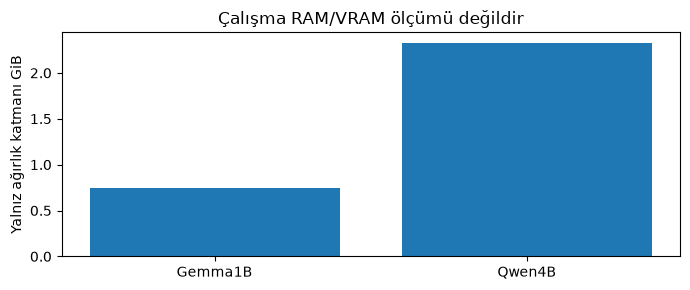

In [2]:
display(pd.DataFrame([{'Ölçüm':h['captured_at'],'Boş RAM GiB':h['RAM']['available']/2**30,'Boş VRAM MiB':h['GPU']['free_MiB']}]))
fig,ax=plt.subplots(figsize=(7,3));ax.bar(['Gemma1B','Qwen4B'],[806058400/2**30,2497280480/2**30]);ax.set_ylabel('Yalnız ağırlık katmanı GiB');ax.set_title('Çalışma RAM/VRAM ölçümü değildir')
F=ROOT/'reports/figures/WP12/gemma1b_candidate_v1';F.mkdir(parents=True,exist_ok=True);fig.tight_layout();fig.savefig(F/'weight_sizes.png',dpi=150);plt.show()

**Yorum:**Daha küçük ağırlık daha düşük potansiyel yük sağlar; runtime/KV/diğer süreçler hesaba katılmadan eşik düşürülmez.3GiB host RAM/2560MiB VRAM kapısı aynen kalır; gerçek tepe bellek ve Türkçe kaynak sadakati ölçülmedi.

In [3]:
display(pd.DataFrame([json.loads((Q/'conditional_run_record.json').read_text(encoding='utf-8'))]).T)
display(pd.DataFrame(json.loads((Q/'existing_Qwen_user_runs_readonly_review.json').read_text(encoding='utf-8'))))
print((Q/'powershell_parse_check.txt').read_text(encoding='utf-8'))
for name in ['test_wp12_gemma_smoke_review.py.log','test_wp12_user_smoke_review.py.log','test_wp12_llm_preflight.py.log','test_wp12_llm_contract.py.log']:
 print(name);print((Q/name).read_text(encoding='utf-8'))

ParseErrors=0; Gemma script NOT executed

test_wp12_gemma_smoke_review.py.log
test_appcontainer_inference_rejected (test_wp12_gemma_smoke_review.ExternalReviewTests.test_appcontainer_inference_rejected) ... ok
test_below_three_GiB_rejected (test_wp12_gemma_smoke_review.ExternalReviewTests.test_below_three_GiB_rejected) ... ok
test_changed_model_rejected (test_wp12_gemma_smoke_review.ExternalReviewTests.test_changed_model_rejected) ... ok
test_changed_seed_rejected (test_wp12_gemma_smoke_review.ExternalReviewTests.test_changed_seed_rejected) ... ok
test_changed_threshold_rejected (test_wp12_gemma_smoke_review.ExternalReviewTests.test_changed_threshold_rejected) ... ok
test_consistent_technical_fixture_does_not_auto_release (test_wp12_gemma_smoke_review.ExternalReviewTests.test_consistent_technical_fixture_does_not_auto_release) ... ok
test_duplicate_echo_keys_rejected (test_wp12_gemma_smoke_review.ExternalReviewTests.test_duplicate_echo_keys_rejected) ... ok
test_multiple_calls_rejected

,0
candidate_id,WP12-gemma3-1b-it-q4_K_M-candidate-v1
model,gemma3:1b-it-q4_K_M
local_manifest_digest,sha256:313f48e331f7326ce703657512ab64022d8813b...
state,AWAITING_USER_HOST_METADATA_AND_TECHNICAL_SMOKE
actual_smoke_result,None
model_downloaded_by_Codex,False
Codex_local_API_calls,0
Codex_inference_calls,0
source_contract_unchanged,True
frozen_scenario_count,19


,record,record_sha256,integrity_review,status,server_version,is_appcontainer,inference_attempts
0,reports/qa/WP12/user_smoke_runs/20261108_03534...,4c0b3fa91201ac5baa80ad8bebbf7ee1bfce476e56936a...,EXTERNAL_RECORD_CONSISTENT_NO_SMOKE_PASS,STOP_MEMORY_GATE,0.40.6,False,0
1,reports/qa/WP12/user_smoke_runs/20261108_03535...,21a7d4576bf4139ed60041fa32d60cfeb22ab717da407f...,EXTERNAL_RECORD_CONSISTENT_NO_SMOKE_PASS,STOP_MEMORY_GATE,0.40.6,False,0


**Yorum:**Eski gerçek Qwen host kayıtlarında API çalışmış, bellek kapısı durmuş; bunlar Gemma başarısı değildir.54 offline test ve parse kontrolü, gerçek Gemma smoke testi değildir. Kaynak/PDF semantik onayı veya19×3 çalışma yoktur. Kullanıcı çıktısı beklenir; WP13 başlamadı.